In [267]:
from matplotlib import pyplot as plt
import numpy as np 
import os
import pandas as pd 
from pathlib import Path
import sys

In [268]:
from scaling.utils import (
    get_pareto_frontier, get_final_points_from_curve_set,
    functional_form_L0, fit_parametric_form
)

In [269]:
sys.path.append(str(Path(os.getcwd()).parent))
from core.forms import PARAMETRIC_FORMS

In [270]:
PLOT_PATH = Path(os.getcwd()).absolute().parent / "plots"
PLOT_PATH.mkdir(exist_ok=True, parents=True)

In [271]:
try:
    import gdown
except ImportError:
    !uv pip install gdown pyarrow
    import gdown

In [272]:
def fix_overflow(arr: np.ndarray) -> np.ndarray:
    a = arr.astype(np.int64)
    diffs = np.diff(a.astype(np.float64))  # diff in float64 to detect real sign
    wraps = np.cumsum(np.concatenate([[0], (diffs < 0).astype(np.int64)]))
    true_vals_f = a.astype(np.float64) + wraps.astype(np.float64) * (2**64)
    return true_vals_f

In [273]:
file_id = "1vr5Jq1TpTpnkb5CX5mcu2wWQQzbf-bmd"
output = "warmstarting_data.parquet"

# Download
if not os.path.exists(output):
    gdown.download(f"https://drive.google.com/uc?id={file_id}", output, quiet=False)

# Check it downloaded
if os.path.exists(output) and os.path.getsize(output) > 0:
    print(f"Downloaded: {output} ({os.path.getsize(output):,} bytes)")
    df = pd.read_parquet(output)
    print(df.shape)
    display(df.head())
else:
    raise FileNotFoundError("Download failed — check sharing permissions.")

Downloaded: warmstarting_data.parquet (34,527,338 bytes)
(2564036, 34)


tag,tokens,flops,Train Loss,Validation Loss,tkpm,base_N,target_N,shrink,adam_beta_1,adam_beta_2,...,mup,n_layer,n_embd,n_head,warmstart_type,method,shrinking,g_width,g_N,post_hoc_df
0,0,0.000000e+00,10.957504,10.984583,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
1,65536,1.268941e+13,11.012417,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
2,131072,2.537883e+13,10.583125,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
3,196608,3.806824e+13,9.702733,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
4,262144,5.075766e+13,8.710074,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...


In [274]:
df.target_N.unique(), df.tkpm.unique(), df.method.unique(), df.shrink.unique()

(array([  32270848,   77124608,  134561280,  287183360,  610488320,
        1217722368]),
 array([10., 20., 30., 50.,  5.,  1.]),
 <ArrowStringArray>
 ['paws', 'mup', 'net2net']
 Length: 3, dtype: str,
 array([0.2, 0.4, 0.6, 0.8, 1. , 0. ]))

In [275]:
df = df.loc[
    # (df.method == "paws") &
    # (df.shrink.isin([0.4, 1.0]))
    (df.method != "net2net") &
    (df.shrink == 0.4)
]

In [276]:
df.target_N.unique(), df.tkpm.unique(), df.method.unique(), df.shrink.unique()

(array([  32270848,   77124608,  134561280,  287183360,  610488320,
        1217722368]),
 array([10., 20., 30., 50.]),
 <ArrowStringArray>
 ['paws']
 Length: 1, dtype: str,
 array([0.4]))

In [277]:
_df = get_final_points_from_curve_set(
    df, ["base_N", "target_N", "tkpm", "method"], x_col="flops", y_col="Validation Loss", get_pareto=True
).dropna()

_df_total = get_final_points_from_curve_set(
    df, ["base_N", "target_N", "tkpm", "method"], x_col="flops", y_col="Validation Loss", get_pareto=False
).dropna()

In [278]:
best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _df["flops"].values, _df["Validation Loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)

<Figure size 640x480 with 0 Axes>

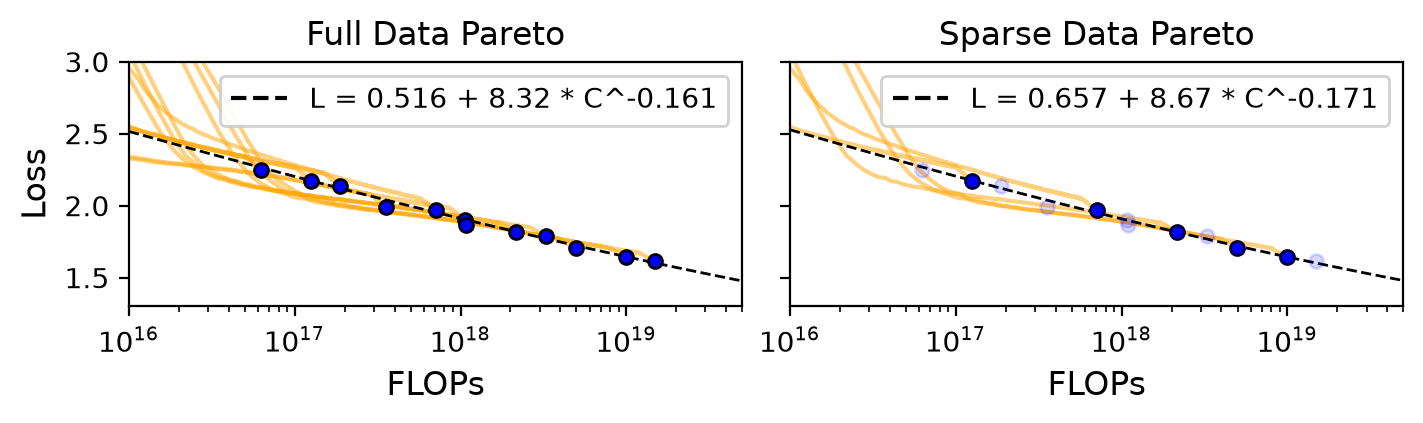

In [279]:
from matplotlib.lines import Line2D

plt.clf()

fig, axes = plt.subplots(1, 2, figsize=(7, 2), dpi=200, sharex=True, sharey=True, constrained_layout=True)

ax = axes[0]
for idx, row in _df.iterrows():
    _lc_df = df.loc[
        (df.base_N == row.base_N) &
        (df.target_N == row.target_N) &
        (df.tkpm == row.tkpm),
        ["flops", "Validation Loss"]
    ].dropna()
    ax.plot(_lc_df["flops"], _lc_df["Validation Loss"], alpha=0.5, color="orange")
    ax.scatter(row["flops"], row["Validation Loss"], color="blue", s=25, zorder=10, marker="o", edgecolor="black")

_flops = np.logspace(16, 20, 100)
ax.plot(
    _flops, PARAMETRIC_FORMS["L0"].func(_flops, best_params), 
    color="black", linestyle="--", linewidth=1
)

ax.set_ylim(1.3, 3)
ax.set_xlim(1e16, 5e19)
ax.set_xscale("log")

# --- custom legend ---
L0, A, alpha = best_params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Full Data Pareto", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_xlabel("FLOPs", fontsize=12)

##############

# subset_idx = [0, 2, 5, 7, 9, 10]
subset_idx = [1, 4, 7, 9, 10]
# subset_idx = [1, 3, 5, 7, 9, 11]
_subset_df = _df.iloc[subset_idx]

### refit params
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _subset_df["flops"].values, _subset_df["Validation Loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)

ax = axes[1]
for idx, row in _subset_df.iterrows():
    _lc_df = df.loc[
        (df.base_N == row.base_N) &
        (df.target_N == row.target_N) &
        (df.tkpm == row.tkpm),
        ["flops", "Validation Loss"]
    ].dropna()
    ax.plot(_lc_df["flops"], _lc_df["Validation Loss"], alpha=0.5, color="orange")
    ax.scatter(row["flops"], row["Validation Loss"], color="blue", s=25, zorder=10, marker="o", edgecolor="black")

ax.scatter(
    _df["flops"], _df["Validation Loss"], 
    color="blue", s=25, zorder=10, marker="o", edgecolor="blue", alpha=0.15
)

_flops = np.logspace(16, 20, 100)
ax.plot(
    _flops, PARAMETRIC_FORMS["L0"].func(_flops, _best_params), 
    color="black", linestyle="--", linewidth=1
)

ax.set_ylim(1.3, 3)
ax.set_xlim(1e16, 5e19)
ax.set_xscale("log")

# --- custom legend ---
L0, A, alpha = _best_params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Sparse Data Pareto", fontsize=12)
ax.set_xlabel("FLOPs", fontsize=12)

plt.savefig(PLOT_PATH / "figure1_warmstarting_data.pdf", dpi=200, bbox_inches="tight")

In [280]:
for key, _df in df.groupby(["base_N", "target_N", "tkpm", "method"]):
    if key[2] == 50.0:
        print(key[2], _df.shape)
        break

50.0 (58987, 34)


In [281]:
_df.loc[_df["Validation Loss"].notna(), ["flops", "Validation Loss"]]

tag,flops,Validation Loss
2226069,0.000000e+00,8.345583
2226093,1.809970e+17,3.192164
2226118,3.695354e+17,2.553458
2226143,5.580739e+17,2.265119
2226168,7.466124e+17,2.097983
...,...,...
2284968,4.441891e+20,1.405687
2284993,4.443777e+20,1.405673
2285018,4.445662e+20,1.405656
2285043,4.447548e+20,1.405649


---

In [282]:
_final_points_df = pd.DataFrame()
for key, _df in df.groupby(["base_N", "target_N", "tkpm", "method"]):
    
    _lc_df = _df.loc[_df["Validation Loss"].notna(), ["flops", "Validation Loss"]]
    _final_points_df = pd.concat([_final_points_df, _lc_df.iloc[[-1]]], ignore_index=True)

<Figure size 640x480 with 0 Axes>

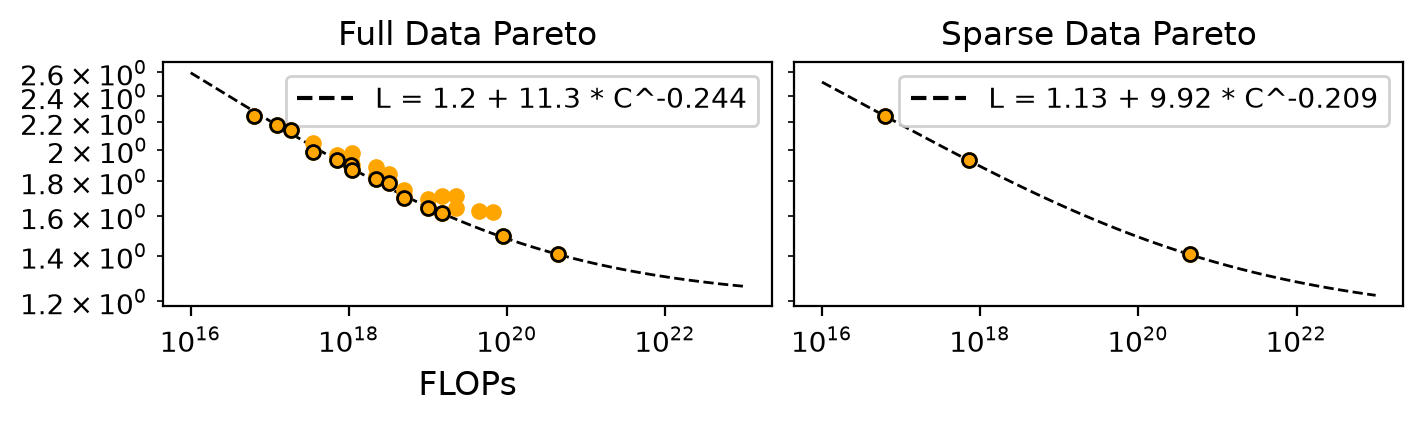

In [283]:
plt.clf()

fig, axes = plt.subplots(1, 2, figsize=(7, 2), dpi=200, sharex=True, sharey=True, constrained_layout=True)

_plot_flops = np.logspace(16, 23, 100)

# fitting on all final points

ax = axes[0]
_all_pareto = get_pareto_frontier(_final_points_df, x_name="flops", y_name="Validation Loss")
_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _all_pareto["flops"], _all_pareto["Validation Loss"],
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
ax.scatter(
    _final_points_df["flops"], _final_points_df["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o"
)
ax.scatter(
    _all_pareto["flops"], _all_pareto["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o", edgecolor="black"
)
ax.plot(
    _plot_flops,
    PARAMETRIC_FORMS["L0"].func(_plot_flops, _params),
    color="black", linestyle="--", linewidth=1
)
L0, A, alpha = _params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Full Data Pareto", fontsize=12)
ax.set_xlabel("FLOPs", fontsize=12)
ax.set_xscale("log")
ax.set_yscale("log")

# fitting on all only first and last points

ax = axes[1]
_mid_id = len(_final_points_df) // 2
_pareto = get_pareto_frontier(_final_points_df.iloc[[0, _mid_id, -1]], x_name="flops", y_name="Validation Loss")
_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _pareto["flops"], _pareto["Validation Loss"],
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
ax.scatter(
    _final_points_df.iloc[[0, _mid_id, -1]]["flops"], _final_points_df.iloc[[0, _mid_id, -1]]["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o"
)
ax.scatter(
    _pareto["flops"], _pareto["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o", edgecolor="black"
)
ax.plot(
    _plot_flops,
    PARAMETRIC_FORMS["L0"].func(_plot_flops, _params),
    color="black", linestyle="--", linewidth=1
)
L0, A, alpha = _params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Sparse Data Pareto", fontsize=12)        
ax.set_yscale("log")
ax.set_xscale("log")

<Figure size 640x480 with 0 Axes>

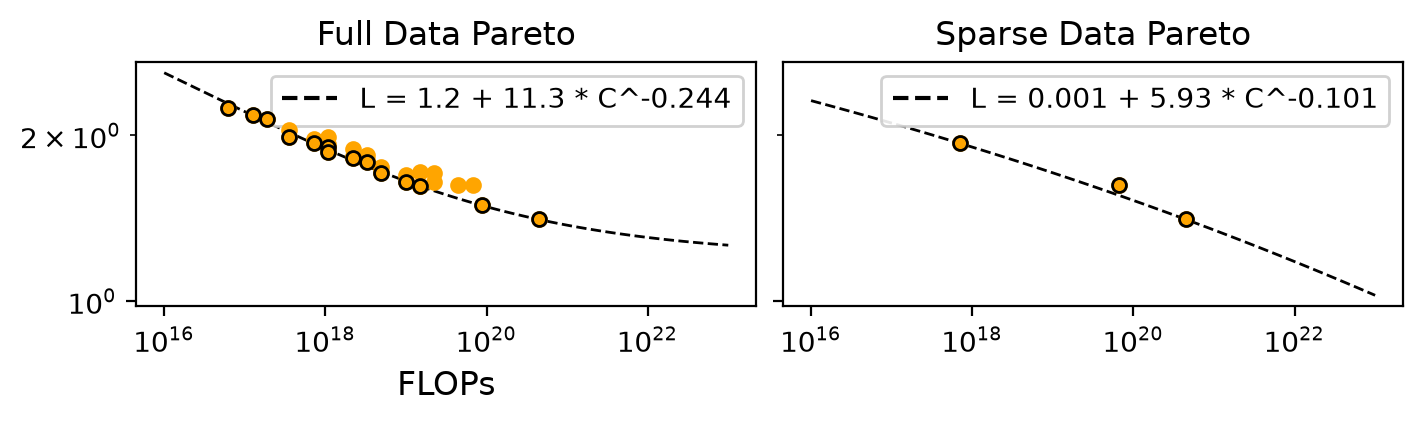

In [284]:
plt.clf()

fig, axes = plt.subplots(1, 2, figsize=(7, 2), dpi=200, sharex=True, sharey=True, constrained_layout=True)

_plot_flops = np.logspace(16, 23, 100)

# fitting on all final points

ax = axes[0]
_all_pareto = get_pareto_frontier(_final_points_df, x_name="flops", y_name="Validation Loss")
_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _all_pareto["flops"], _all_pareto["Validation Loss"],
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
ax.scatter(
    _final_points_df["flops"], _final_points_df["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o"
)
ax.scatter(
    _all_pareto["flops"], _all_pareto["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o", edgecolor="black"
)
ax.plot(
    _plot_flops,
    PARAMETRIC_FORMS["L0"].func(_plot_flops, _params),
    color="black", linestyle="--", linewidth=1
)
L0, A, alpha = _params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Full Data Pareto", fontsize=12)
ax.set_xlabel("FLOPs", fontsize=12)
ax.set_xscale("log")
ax.set_yscale("log")

# fitting on all only first and last points

ax = axes[1]
_mid_id = len(_final_points_df) // 2
_pareto = get_pareto_frontier(_final_points_df.iloc[[_mid_id - 2, _mid_id, -1]], x_name="flops", y_name="Validation Loss")
_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _pareto["flops"], _pareto["Validation Loss"],
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
ax.scatter(
    _final_points_df.iloc[[_mid_id - 2, _mid_id, -1]]["flops"], _final_points_df.iloc[[_mid_id - 2, _mid_id, -1]]["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o"
)
ax.scatter(
    _pareto["flops"], _pareto["Validation Loss"],
    color="orange", s=25, zorder=10, marker="o", edgecolor="black"
)
ax.plot(
    _plot_flops,
    PARAMETRIC_FORMS["L0"].func(_plot_flops, _params),
    color="black", linestyle="--", linewidth=1
)
L0, A, alpha = _params
handles = [
    Line2D([], [], color="black", linestyle="--", label=f"L = {L0:.3g} + {A:.3g} * C^{alpha:.3g}"),
]
ax.legend(handles=handles, loc="upper right", fontsize=10, framealpha=0.9)
ax.set_title("Sparse Data Pareto", fontsize=12)        
ax.set_yscale("log")
ax.set_xscale("log")

In [285]:
PARAMETRIC_FORMS["L0"].bounds

[(0.001, 4.0), (None, None), (-1.0, 0.0)]

In [286]:
_df_total.tkpm.unique()

array([10., 20., 30.])

---

In [287]:
_full_pareto = get_pareto_frontier(df, x_name="flops", y_name="Validation Loss")


In [288]:
df.columns

Index(['tokens', 'flops', 'Train Loss', 'Validation Loss', 'tkpm', 'base_N',
       'target_N', 'shrink', 'adam_beta_1', 'adam_beta_2', 'adam_eps',
       'block_size', 'max_lr', 'min_lr', 'warmup_fraction',
       'cooldown_fraction', 'cooldown_lr_decay_factor', 'scheduler_type',
       'scheduler_lr_decay_factor', 'micro_batch_size', 'accumulation_iters',
       'devices', 'weight_decay', 'seed', 'mup', 'n_layer', 'n_embd', 'n_head',
       'warmstart_type', 'method', 'shrinking', 'g_width', 'g_N',
       'post_hoc_df'],
      dtype='str', name='tag')

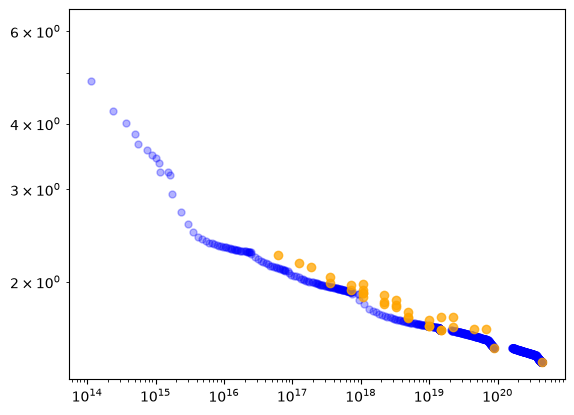

In [289]:
plt.clf()

g = df.groupby(["base_N", "target_N", "tkpm", "shrink", "method"]).groups
for k, v in g.items():
    _lc_df = df.loc[v, ["flops", "Validation Loss"]].dropna()
    _lc_df.sort_values(by="flops", inplace=True)
    plt.scatter(_lc_df["flops"].values[-1], _lc_df["Validation Loss"].values[-1], alpha=0.75, color="orange", zorder=10)
plt.plot(_full_pareto["flops"], _full_pareto["Validation Loss"], color="blue", marker="o", markersize=5, linestyle="None", alpha=0.3)
plt.xscale("log")
plt.yscale("log")

In [290]:
df.target_N.unique()

array([  32270848,   77124608,  134561280,  287183360,  610488320,
       1217722368])

In [291]:
_df = df.loc[(df.target_N == 1217722368) & (df.tkpm == 50)]
_df["flops"] = fix_overflow(6 * 1217722368 * _df.tokens)
_df.tail(3)

tag,tokens,flops,Train Loss,Validation Loss,tkpm,base_N,target_N,shrink,adam_beta_1,adam_beta_2,...,mup,n_layer,n_embd,n_head,warmstart_type,method,shrinking,g_width,g_N,post_hoc_df
2285053,60882812928,4.448302e+20,1.393305,NaN,50.0,610488320,1217722368,0.4,0.9,0.95,...,True,8,3072,48,snp_zeros_with_mup,paws,0.4,6.0,1.0,NaN
2285054,60883845120,4.448377e+20,1.387229,NaN,50.0,610488320,1217722368,0.4,0.9,0.95,...,True,8,3072,48,snp_zeros_with_mup,paws,0.4,6.0,1.0,NaN
2285055,60884877312,4.448453e+20,1.382005,1.405649,50.0,610488320,1217722368,0.4,0.9,0.95,...,True,8,3072,48,snp_zeros_with_mup,paws,0.4,6.0,1.0,NaN


In [292]:
_df = df.loc[(df.target_N == 1217722368) & (df.tkpm == 10)]
_df["flops"] = fix_overflow(6 * 1217722368 * _df.tokens)
_df.tail(3)

tag,tokens,flops,Train Loss,Validation Loss,tkpm,base_N,target_N,shrink,adam_beta_1,adam_beta_2,...,mup,n_layer,n_embd,n_head,warmstart_type,method,shrinking,g_width,g_N,post_hoc_df
2226066,12174704640,8.895246e+19,1.468371,NaN,10.0,610488320,1217722368,0.4,0.9,0.95,...,True,8,3072,48,snp_zeros_with_mup,paws,0.4,6.0,1.0,/work/dlclarge1/mallik-warmstarting/warmstarti...
2226067,12175736832,8.896000e+19,1.477706,1.496509,10.0,610488320,1217722368,0.4,0.9,0.95,...,True,8,3072,48,snp_zeros_with_mup,paws,0.4,6.0,1.0,/work/dlclarge1/mallik-warmstarting/warmstarti...
2226068,12176769024,8.896754e+19,NaN,NaN,10.0,610488320,1217722368,0.4,0.9,0.95,...,True,8,3072,48,snp_zeros_with_mup,paws,0.4,6.0,1.0,/work/dlclarge1/mallik-warmstarting/warmstarti...


In [293]:
_df = df.loc[(df.target_N == 610488320) & (df.tkpm == 30)]
_df["flops"] = fix_overflow(6 * 610488320 * _df.tokens)
_df.tail(3)

tag,tokens,flops,Train Loss,Validation Loss,tkpm,base_N,target_N,shrink,adam_beta_1,adam_beta_2,...,mup,n_layer,n_embd,n_head,warmstart_type,method,shrinking,g_width,g_N,post_hoc_df
1267924,18312069120,6.707583e+19,1.610645,NaN,30.0,14562560,610488320,0.4,0.9,0.95,...,True,8,2048,32,snp_zeros_with_mup,paws,0.4,16.0,41.921772,/work/dlclarge1/mallik-warmstarting/warmstarti...
1267925,18312855552,6.707871e+19,1.603935,NaN,30.0,14562560,610488320,0.4,0.9,0.95,...,True,8,2048,32,snp_zeros_with_mup,paws,0.4,16.0,41.921772,/work/dlclarge1/mallik-warmstarting/warmstarti...
1267926,18313641984,6.708159e+19,1.604456,1.62524,30.0,14562560,610488320,0.4,0.9,0.95,...,True,8,2048,32,snp_zeros_with_mup,paws,0.4,16.0,41.921772,/work/dlclarge1/mallik-warmstarting/warmstarti...


---

## PRE-PROCESSING WARMSTARTING DATA

In [294]:
# download from GDrive

file_id = "1vr5Jq1TpTpnkb5CX5mcu2wWQQzbf-bmd"
output = "warmstarting_data.parquet"

# Download
if not os.path.exists(output):
    gdown.download(f"https://drive.google.com/uc?id={file_id}", output, quiet=False)

# Check it downloaded
if os.path.exists(output) and os.path.getsize(output) > 0:
    print(f"Downloaded: {output} ({os.path.getsize(output):,} bytes)")
    df = pd.read_parquet(output)
    print(df.shape)
    display(df.head())
else:
    raise FileNotFoundError("Download failed — check sharing permissions.")

Downloaded: warmstarting_data.parquet (34,527,338 bytes)
(2564036, 34)


tag,tokens,flops,Train Loss,Validation Loss,tkpm,base_N,target_N,shrink,adam_beta_1,adam_beta_2,...,mup,n_layer,n_embd,n_head,warmstart_type,method,shrinking,g_width,g_N,post_hoc_df
0,0,0.000000e+00,10.957504,10.984583,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
1,65536,1.268941e+13,11.012417,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
2,131072,2.537883e+13,10.583125,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
3,196608,3.806824e+13,9.702733,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...
4,262144,5.075766e+13,8.710074,NaN,10.0,14562560,32270848,0.2,0.9,0.95,...,True,8,256,4,snp_zeros_with_mup,paws,0.2,2.0,2.216015,/work/dlclarge1/mallik-warmstarting/warmstarti...


In [295]:
# summary

print(df.target_N.unique(), df.tkpm.unique(), df.method.unique(), df.shrink.unique())
print()
print(df.columns)
print(df.shape)

[  32270848   77124608  134561280  287183360  610488320 1217722368] [10. 20. 30. 50.  5.  1.] <ArrowStringArray>
['paws', 'mup', 'net2net']
Length: 3, dtype: str [0.2 0.4 0.6 0.8 1.  0. ]

Index(['tokens', 'flops', 'Train Loss', 'Validation Loss', 'tkpm', 'base_N',
       'target_N', 'shrink', 'adam_beta_1', 'adam_beta_2', 'adam_eps',
       'block_size', 'max_lr', 'min_lr', 'warmup_fraction',
       'cooldown_fraction', 'cooldown_lr_decay_factor', 'scheduler_type',
       'scheduler_lr_decay_factor', 'micro_batch_size', 'accumulation_iters',
       'devices', 'weight_decay', 'seed', 'mup', 'n_layer', 'n_embd', 'n_head',
       'warmstart_type', 'method', 'shrinking', 'g_width', 'g_N',
       'post_hoc_df'],
      dtype='str', name='tag')
(2564036, 34)


In [296]:
# print columns that have no variance or unique is 0

# for col in df.columns:
#     if df[col].nunique() > 1:
#         print(f"{col}: {df[col].nunique()} unique values")


In [297]:
# filters

df["N"] = df.target_N.values
df["D"] = df.tokens
df["gbsz"] = df.micro_batch_size * df.accumulation_iters * df.devices
df["lr"] = df.max_lr

HYPERPARAMETERS = [
    "N", "D", "flops", "Train Loss", "Validation Loss", "tkpm",
    "base_N", "shrink", "method", "g_N", "g_width", "gbsz", "lr"
]

df = df.loc[df.method != "net2net", HYPERPARAMETERS]
display(df.head())
print(df.shape)


tag,N,D,flops,Train Loss,Validation Loss,tkpm,base_N,shrink,method,g_N,g_width,gbsz,lr
0,32270848,0,0.000000e+00,10.957504,10.984583,10.0,14562560,0.2,paws,2.216015,2.0,64,0.003
1,32270848,65536,1.268941e+13,11.012417,NaN,10.0,14562560,0.2,paws,2.216015,2.0,64,0.003
2,32270848,131072,2.537883e+13,10.583125,NaN,10.0,14562560,0.2,paws,2.216015,2.0,64,0.003
3,32270848,196608,3.806824e+13,9.702733,NaN,10.0,14562560,0.2,paws,2.216015,2.0,64,0.003
4,32270848,262144,5.075766e+13,8.710074,NaN,10.0,14562560,0.2,paws,2.216015,2.0,64,0.003


(2293593, 13)


In [298]:
# checking unique columns

for col in df.columns:
    if df[col].nunique() <= 1:
        print(f"{col}: {df[col].nunique()} unique values")

In [299]:
# collecting final points from each curve

final_points_df = pd.DataFrame()
for key, _id in df.groupby(["N", "tkpm", "base_N", "shrink", "method", "gbsz", "lr"]).groups.items():
    _df = df.loc[_id]
    _lc_df = _df.loc[_df["Validation Loss"].notna()].sort_values(by="flops").sort_values(by="flops").iloc[-1]
    if not _lc_df.empty:
        final_points_df = pd.concat([final_points_df, _lc_df.to_frame().T], ignore_index=True)
# final_points_df.drop(columns=["tkpm"], inplace=True)
display(final_points_df.head())
print(final_points_df.shape)

tag,N,D,flops,Train Loss,Validation Loss,tkpm,base_N,shrink,method,g_N,g_width,gbsz,lr
0,32270848,32178176,6230502159679488.0,2.398622,2.981819,1.0,14562560,0.0,mup,2.216015,2.0,64,0.003
1,32270848,161284096,31228647281000448.0,2.078954,2.378685,5.0,14562560,0.0,mup,2.216015,2.0,64,0.003
2,32270848,322633728,62469983975768064.0,2.17994,2.259872,10.0,14562560,0.0,mup,2.216015,2.0,64,0.003
3,32270848,322633728,62469983975768064.0,2.089092,2.252899,10.0,14562560,0.2,paws,2.216015,2.0,64,0.003
4,32270848,322633728,62469983975768064.0,2.082877,2.244467,10.0,14562560,0.4,paws,2.216015,2.0,64,0.003


(150, 13)


In [300]:
# saving

final_points_df.to_csv(Path(os.getcwd()).absolute() / "final_points_df.csv", index=False)